# Napovedovanje ocen z nevronsko mrežo (PyTorch)

Iz podatkov (procent točk) naučimo majhno nevronsko mrežo, ki napoveduje oceno od 1 do 5.

**Potek:**
1. Generiramo sintetične podatke
2. Naložimo podatke in jih razdelimo na učenje / validacijo / testiranje
3. Zgradimo mrežo in jo treniramo
4. Izmerimo natančnost na testni množici
5. Shranimo model in ročno preverimo napovedi

## Uvoz knjižnic

Najprej uvozimo vse potrebne knjižnice: `torch` za nevronsko mrežo, `numpy` za delo s podatki, `json` in `os` za shranjevanje zgodovine zagonov ter `random` in `csv` za generiranje podatkov.

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import json
import os
import random as r
import csv
import matplotlib.pyplot as plt
from datetime import datetime

# Izberemo napravo: GPU (če je na voljo), sicer CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Uporabljam napravo: GPU (CUDA)")
else:
    device = torch.device("cpu")
    print("Uporabljam napravo: CPU")

Uporabljam napravo: CPU


## 1. Generiranje podatkov

Funkcija `create_data` generira naključne pojence: za vsako vrstico izbere naključen procent (0–100) in mu priredi oceno po pravilih:

| Procent | Ocena |
|---|---|
| < 49 | 1 |
| 49 – 61.9 | 2 |
| 62 – 74.9 | 3 |
| 75 – 88.9 | 4 |
| ≥ 89 | 5 |

Podatke zapiše v `data.csv` z glavo `percent,grade`.

In [14]:
def create_data(num_rows):
    rows = []
    for i in range(num_rows):
        percent = round(r.random() * 100, 1)
        if percent < 49:
            grade = 1
        elif percent < 62:
            grade = 2
        elif percent < 75:
            grade = 3
        elif percent < 89:
            grade = 4
        else:
            grade = 5
        rows.append((percent, grade))

    with open("data.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["percent", "grade"])   # header
        w.writerows(rows)

## 2. Nastavitve zagona

Nastavimo različne argumente


- `data_rows` – število vrstic podatkov (max 1,000,000)
- `epoch_count` – število epoh (max 10,000)
- `training_percent` – odstotek podatkov za treniranje (0–80)
- `eval_percent` – odstotek podatkov za validacijo (0–15)
- preostanek podatkov gre za testiranje

In [40]:
data_rows = 1000      # število vrstic podatkov
epoch_count = 2000       # število epoh
training_percent = 80.0  # odstotek za treniranje
eval_percent = 10.0      # odstotek za validacijo

## 3. Nalaganje in priprava podatkov

Podatke preberemo iz CSV datoteke in jih pretvorimo v PyTorch tenzorje:

- **X** (vhod): procent, normaliziran z deljenjem z 100, da je v območju 0–1 → lažje učenje
- **y** (izhod): ocene premaknemo z `-1`, da so od 0 do 4, ker `CrossEntropyLoss` pričakuje razrede, indeksirane od 0

In [41]:
create_data(data_rows) # generira dataset

# naloži podatke iz CSV datoteke in jih pretvori v PyTorch tenzorje
data = np.loadtxt("data.csv", delimiter=",", skiprows=1)
X = torch.tensor(data[:, 0:1], dtype=torch.float32).to(device) / 100.0  # procente spremenimo med 0 in 1
y = torch.tensor(data[:, 1] - 1, dtype=torch.long).to(device)          # ocene premaknemo da so od 0 do 4

print(f"Skupaj podatkov: {len(data)}")
print("Prvih 5 vrstic:", data[:5].tolist())

Skupaj podatkov: 1000
Prvih 5 vrstic: [[19.6, 1.0], [80.7, 4.0], [51.6, 2.0], [2.7, 1.0], [80.2, 4.0]]


## 4. Razdelitev podatkov: učenje / validacija / testiranje

Podatke premešamo (`torch.randperm`) — če bi uporabljali podatke, ki ne bi bili naključno generirani, bi bilo to potrebno, da skupine niso urejene. Nato jih razdelimo glede na podana odstotka:

- **Učenje** (`training_percent` %) – nanj se model uči
- **Validacija** (`eval_percent` %) – med učenjem spremljamo, ali model se je učil splošno (brez preprilagoditve)
- **Testiranje** (preostanek) – končna ocena modela na podatkih, ki jih ni nikoli videl

In [42]:
# premešamo podatke (če bi uporabljali podatke, ki nebi bili naključno generirani, bi bilo to potrebno)
num_samples = len(data)
indices = torch.randperm(num_samples)

# izračunamo velikost posameznih skupin glede na podani odstotek
train_size = int(training_percent / 100 * num_samples)
val_size = int(eval_percent / 100 * num_samples)

# razdelimo podatke na trening, validacijo in testiranje
train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]  # preostanek podatkov bo za testiranje

# ustvarimo posamezne tenzorje za trening, validacijo in testiranje
X_train, y_train = X[train_idx], y[train_idx]   # treniranje
X_val,   y_val   = X[val_idx],   y[val_idx]     # validacija
X_test,  y_test  = X[test_idx],  y[test_idx]    # testiranje

print(f"treniranje: {train_size} | validacija: {val_size} | testiranje: {len(test_idx)}")

treniranje: 800 | validacija: 100 | testiranje: 100


## 5. Model, izguba in optimizer

Model je majhen MLP (večslojni perceptron):

- **Vhodna plast** (`Linear(1, 7)`): sprejme 1 vhod (procent) in vrne 7 skritih vrednosti
- **ReLU**: aktivacijska funkcija, ki doda nelinearnost (brez nje bi bil model samo linearen)
- **Izhodna plast** (`Linear(7, 5)`): vrne 5 vrednosti (logite) — eno za vsako oceno 0–4

- **CrossEntropyLoss** meri razliko med napovedanimi in dejanskimi ocenami (za klasifikacijo)
- **SGD** (stohastični gradientni spust) posodablja uteži modela na podlagi izračunanih gradientov, z učno hitrostjo `lr=0.05`


In [43]:
# ustvarimo model
model = nn.Sequential(
    nn.Linear(1, 7),  # vhodna plast ki sprejme 1 vhod
    nn.ReLU(),        # aktivacijska funkcija ReLU
    nn.Linear(7, 5)   # izhodna plast ki vrne 5 izhodnih vrednosti (grade 0-4)
).to(device)

criterion = nn.CrossEntropyLoss()                  # Loss function ki meri razliko med napovedanimi in dejanskimi ocenami (grade 0-4)
optimizer = optim.SGD(model.parameters(), lr=0.05) # Optimizer za posodabljanje teže modela na podlagi izračunanih gradientov

print(model)

Sequential(
  (0): Linear(in_features=1, out_features=7, bias=True)
  (1): ReLU()
  (2): Linear(in_features=7, out_features=5, bias=True)
)


## 6. Treniranje modela

Vsaka epoha poteka v štirih korakih:

1. `optimizer.zero_grad()` — resetiramo gradientne vrednosti, da preprečimo akumulacijo iz prejšnjih epoh
2. `criterion(model(X_train), y_train)` — **forward pass**: izračunamo napovedi modela in primerjamo z dejanskimi ocenami, da dobimo loss
3. `loss.backward()` — **backward pass**: backpropagation za izračun gradientov glede na loss
4. `optimizer.step()` — posodobimo teže modela na podlagi izračunanih gradientov

Vsakih 200 epoh izpišemo validacijski loss, da spremljamo napredek modela. Pri tem uporabimo `torch.no_grad()` (brez računanja gradientov) in na kratko preklopnemo model v `eval()` način, nato pa nazaj v `train()`.

In [44]:
# treniranje modela čez vse epohe
train_losses = []  # za kasnejši graff
val_losses = []

for epoch in range(epoch_count):
    optimizer.zero_grad()                     # Resetiramo gradientne vrednosti, da preprečimo akumulacijo iz prejšnjih epoh
    loss = criterion(model(X_train), y_train) # Forward pass: izračunamo napovedi modela in primerjamo z dejanskimi ocenami, da dobimo loss
    loss.backward()                           # Backward pass: backpropagation za izračun gradientov glede na loss
    optimizer.step()                          # posodobimo teže modela na podlagi izračunanih gradientov
    train_losses.append(loss.item())

    # Vsakih 200 epoh izpišemo validacijski loss, da spremljamo napredek modela
    if (epoch + 1) % 200 == 0:
        model.eval()                          # evaluacija modela
        with torch.no_grad():
            val_loss = criterion(model(X_val), y_val) # izračunamo validacijski loss na validacijskem setu
            val_losses.append((epoch + 1, val_loss.item()))
            print(f"epoha {epoch+1} | Validacijski Loss: {val_loss.item():.4f}")
        model.train()                         # model se vrne v trenirni način, da lahko nadaljujemo s treniranjem

epoha 200 | Validacijski Loss: 1.0294
epoha 400 | Validacijski Loss: 0.8032
epoha 600 | Validacijski Loss: 0.7001
epoha 800 | Validacijski Loss: 0.6321
epoha 1000 | Validacijski Loss: 0.5782
epoha 1200 | Validacijski Loss: 0.5332
epoha 1400 | Validacijski Loss: 0.4946
epoha 1600 | Validacijski Loss: 0.4612
epoha 1800 | Validacijski Loss: 0.4320
epoha 2000 | Validacijski Loss: 0.4064


## 7. Graff izgube (loss)

Prikaz trenirne in validacijske izgube skozi epohe — to je dodatna vizualizacija, ki v terminalski verziji ni bila mogoča. Če validacijska izguba raste, medtem ko trenirna pada, se model preprilagodi (overfitting).

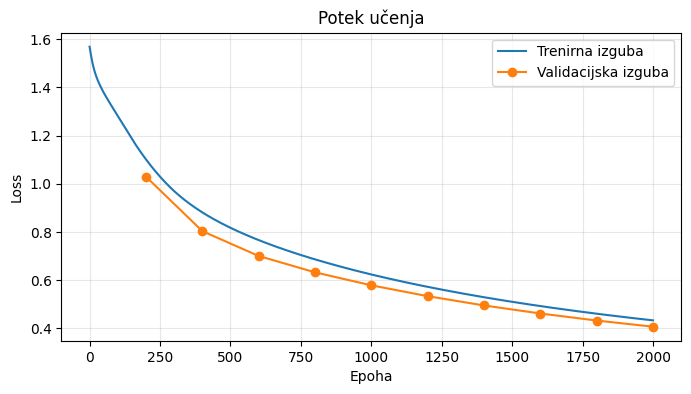

In [45]:
# vizualizacija poteka učenja
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Trenirna izguba")
if val_losses:
    ve, vl = zip(*val_losses)
    plt.plot(ve, vl, "o-", label="Validacijska izguba")
plt.xlabel("Epoha")
plt.ylabel("Loss")
plt.title("Potek učenja")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Testiranje modela

Model nastavimo v `eval()` način in z `torch.no_grad()` napovedujemo na testnem setu (podatkih, ki jih model ni nikoli videl):

- **logits** — surove izhodne vrednosti modela
- **argmax** — glede na izhodne vrednosti modela izberemo tisto z največjo vrednostjo kot napovedano oceno
- **accuracy** — delež pravilno napovedanih ocen glede na dejanske ocene

In [46]:
# Testiranje modela na testnem setu in izračun natančnosti (accuracy)
model.eval()                                  # model nastavimo v eval mode
with torch.no_grad():
    logits = model(X_test)                    # napovedi modela na testnem setu
    predictions = torch.argmax(logits, dim=1) # glede na izhodne vrednosti modela izberemo tisto z največjo verjetnostjo kot napovedano oceno
    accuracy = (predictions == y_test).float().mean() # delež pravilno napovedanih ocen
    final_accuracy = accuracy.item() * 100
    print(f"Končni Accuracy modela: {final_accuracy:.1f}%")
    print(f"uporabljeni podatki: {data_rows} | treniranje: {train_size} | validacija: {val_size} | testiranje: {len(test_idx)} | število epoh: {epoch_count}")

Končni Accuracy modela: 96.0%
uporabljeni podatki: 1000 | treniranje: 800 | validacija: 100 | testiranje: 100 | število epoh: 2000


## 9. Shranjevanje zagona (run-a) v mapo `saved_models`

Model in metapodatki se shranijo, da lahko  pozneje primerjamo:

- **A)** uteži modela shranimo z `torch.save(model.state_dict(), ...)` v `.pth` datoteko
- **B)** pripravimo slovar `run_data` z vsemi pomembnimi podatki o zagonu (vključno z relativno potjo do modela)
- **C)** zapišemo/dodamo v skupno JSON datoteko `model_runs.json` z vsemi zagoni

In [47]:
# SHRANJEVANJE ZAGONA (RUN-A) V MAPO "saved_models"
models_dir = "saved_models"
os.makedirs(models_dir, exist_ok=True)  # Ustvari mapo, če ne obstaja

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
run_name = f"run_{timestamp}_epochs_{epoch_count}_rows_{data_rows}"
model_filepath = os.path.join(models_dir, f"{run_name}.pth")

# A) Shranimo uteži modela v mapo
torch.save(model.state_dict(), model_filepath)

# B) Pripravimo podatke za JSON zapis (shranimo relativno pot do modela)
run_data = {
    "timestamp": timestamp,
    "data_rows": data_rows,
    "epoch_count": epoch_count,
    "training_percent": training_percent,
    "eval_percent": eval_percent,
    "train_size": train_size,
    "val_size": val_size,
    "test_size": len(test_idx),
    "final_accuracy": round(final_accuracy, 2),
    "model_file": model_filepath
}

# C) Zapišemo/dodamo v skupno datoteko z vsemi zagoni
history_file = "model_runs.json"
if os.path.exists(history_file):
    with open(history_file, "r") as f:
        try:
            runs_history = json.load(f)
        except json.JSONDecodeError:
            runs_history = []
else:
    runs_history = []

runs_history.append(run_data)

with open(history_file, "w") as f:
    json.dump(runs_history, f, indent=4)

print(f"Zagon uspešno shranjen. Model se nahaja v: {model_filepath}")

Zagon uspešno shranjen. Model se nahaja v: saved_models/run_20261117_160553_epochs_2000_rows_1000.pth


## 10. Ročno preverjanje modela

V terminalski verziji je to bila neskončna zanka z `input()`. V zvezku to rešimo z funkcijo `predict_grade(percent)`, ki jo lahko pokličemo z katerim koli procentom:

- procent pretvorimo v tenzor, normaliziramo med 0 in 1 ter prestavimo na napravo
- **logits** — napoved modela (surove vrednosti)
- **Softmax** pretvori surove vrednosti (logits) v verjetnosti (odstotke)
- **argmax + 1** — izberemo oceno z največjo verjetnostjo in jo prilagodimo nazaj na lestvico 1–5

In [54]:
def predict_grade(percent):
    # ročno preverjanje modela za podani procent (0-100)
    model.eval()
    with torch.no_grad():
        input_tensor = torch.tensor([[percent / 100.0]], dtype=torch.float32).to(device) # pretvorimo procent v tensor in normaliziramo med 0 in 1 ter prestavimo na napravo
        logits = model(input_tensor) # napoved modela (surove vrednosti)

        # Pretvori surove vrednosti (logits) v verjetnosti (odstotke) preko Softmax funkcije
        probabilities = torch.softmax(logits, dim=1)

        prediction = torch.argmax(logits, dim=1).item() + 1 # izberemo oceno z največjo verjetnostjo in jo prilagodimo na 1-5

        print(f"Napovedana ocena za {percent}% je {prediction}")
        probs = {}
        # Zanka za izpis verjetnosti za vsako oceno od 1 do 5
        for grade in range(1, 6):
            prob = probabilities[0][grade - 1].item() * 100
            probs[grade] = prob
            print(f"Ocena {grade}: {prob:.1f}%")
        return prediction, probs

# primer uporabe — spodaj lahko spremeniš procent ali dodaš več klicev
predict_grade(49)

Napovedana ocena za 49% je 1
Ocena 1: 51.3%
Ocena 2: 37.1%
Ocena 3: 10.7%
Ocena 4: 0.8%
Ocena 5: 0.0%


(1,
 {1: 51.3042688369751,
  2: 37.12550103664398,
  3: 10.743960738182068,
  4: 0.8104727603495121,
  5: 0.015797142987139523})

### Grafični prikaz verjetnosti

Dodatna vizualizacija: verjetnosti za posamezne ocene kot stolpčni diagram.

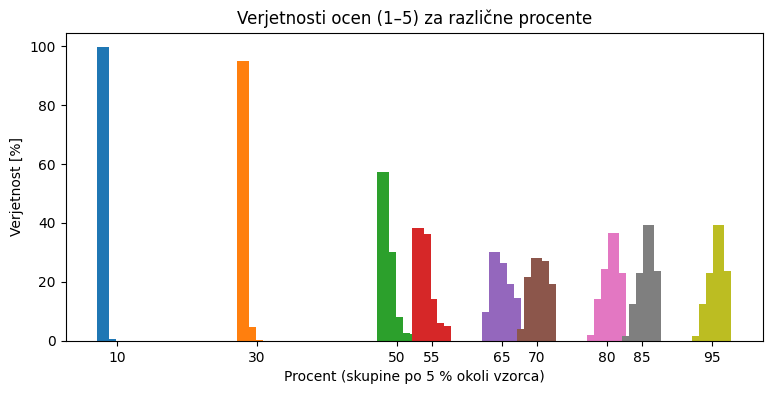

In [32]:
# verjetnosti po ocenah za nekaj primerov procentov
primeri = [10, 30, 50, 55, 65, 70, 80, 85, 95]

fig, ax = plt.subplots(figsize=(9, 4))
model.eval()
with torch.no_grad():
    for p in primeri:
        probs = torch.softmax(model(torch.tensor([[p / 100.0]], dtype=torch.float32).to(device)), dim=1)[0]
        ax.bar([p - 2 + g for g in range(5)], [pr.item() * 100 for pr in probs], width=1.6)

ax.set_xlabel("Procent (skupine po 5 % okoli vzorca)")
ax.set_ylabel("Verjetnost [%]")
ax.set_title("Verjetnosti ocen (1–5) za različne procente")
ax.set_xticks(primeri)
plt.show()

## Povzetek

- Model se nauči meje med ocenami (1–5) iz podatka o procentu
- Meje v podatkih: < 49 → 1, < 62 → 2, < 75 → 3, < 89 → 4, sicer 5
- Natančnost je najnižja blizu mej (npr. ~49 %, ~62 %), kjer je odločitev najtežja
- Vsak zagon se shrani v `saved_models/` in `model_runs.json` za primerjavo